# 3. 检测原理：六个子图，一个被写错的公式

原文图 1 是整篇文章的机理图：三角脉冲 + −10 dB 噪声进入振子 1，两振子在脉冲瞬间
**朝相反方向**突变，差值把同相的正弦策动力抵消，露出脉冲。

这一章把图 1 的 (a)–(f) 六个子图全部重画，然后回答一个必须先定下来的问题：
**输出量到底是 $x_1-x_2$ 还是 $\dot x_1-\dot x_2$？**

这不是学术洁癖。原文图 1(b)、图 8–10 的纵轴标的是 $x_1-x_2$，而 5.2 节正文写
$s_o(t)=\dot x_1-\dot x_2$。**两者差一个微分，选错就无法做幅值估计。**


In [1]:
import sys, json, pathlib
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, "_src")
import c2sim as S

DATA = pathlib.Path("_data")
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10,
    "font.sans-serif": ["Microsoft YaHei", "SimHei", "DejaVu Sans"],
    "axes.unicode_minus": False,
})

def load(name):
    return json.loads((DATA / f"{name}.json").read_text(encoding="utf-8"))

def dual_plot(x, snri, r, xlabel, title="", logx=False, invert=False,
              marks=None, ymax=None):
    fig, ax1 = plt.subplots(figsize=(7.4, 3.5))
    ax1.plot(x, snri, "o-", color="#1f4e79", ms=4, lw=1.2)
    ax1.set_xlabel(xlabel); ax1.set_ylabel("SNRI / dB", color="#1f4e79")
    ax1.tick_params(axis="y", colors="#1f4e79")
    if ymax: ax1.set_ylim(top=ymax)
    ax2 = ax1.twinx()
    ax2.plot(x, r, "s--", color="#8a3b2e", ms=4, lw=1.2)
    ax2.set_ylabel("波形相似度 r", color="#8a3b2e")
    ax2.tick_params(axis="y", colors="#8a3b2e")
    if logx: ax1.set_xscale("log")
    if invert: ax1.invert_xaxis()
    if marks:
        for xv, lab in marks:
            ax1.axvline(xv, color="gray", ls=":", lw=1)
            ax1.text(xv, ax1.get_ylim()[1], lab, fontsize=8, va="top",
                     ha="center", color="#7a2e12")
    ax1.grid(alpha=.2); ax1.set_title(title)
    plt.tight_layout(); plt.show()


In [2]:
z = np.load(DATA / "fig1.npz")
t = z["t"] * 1e6                      # µs
s, sn, so = z["s"], z["sn"], z["so"]
dx, x1, x2, v1, v2 = z["dx"], z["x1"], z["x2"], z["v1"], z["v2"]

print(f"脉冲峰值 {s.max():.3f}，噪声标准差 {np.std(sn - s):.3f}（对应 −10 dB）")
print(f"输出峰值：位移差 {np.abs(dx).max():.4f}   速度差 {np.abs(so).max():.0f}")


脉冲峰值 0.630，噪声标准差 0.200（对应 −10 dB）
输出峰值：位移差 0.0263   速度差 86158


C:\Users\22902\WorkBuddy\毕设\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 7819 (\N{LATIN SMALL LETTER X WITH DOT ABOVE}) missing from font(s) Microsoft YaHei.
  fig.canvas.print_figure(bytes_io, **kw)


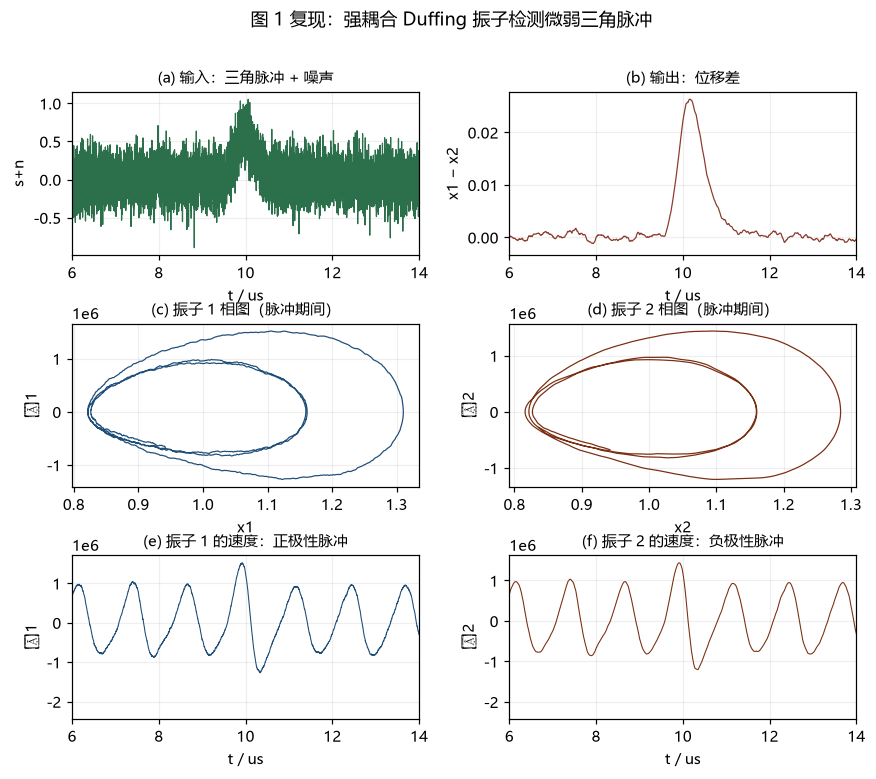

In [3]:
fig = plt.figure(figsize=(9.2, 7.4))
gs = fig.add_gridspec(3, 2, hspace=.42, wspace=.26)

ax = fig.add_subplot(gs[0, 0])
ax.plot(t, sn, color="#2b6f4b", lw=.8); ax.set(xlabel="t / us", ylabel="s+n", xlim=(6, 14))
ax.set_title("(a) 输入：三角脉冲 + 噪声", fontsize=10)

ax = fig.add_subplot(gs[0, 1])
ax.plot(t, dx, color="#8a3b2e", lw=.8); ax.set(xlabel="t / us", ylabel="x1 − x2", xlim=(6, 14))
ax.set_title("(b) 输出：位移差", fontsize=10)

w = (t > 8) & (t < 12)
ax = fig.add_subplot(gs[1, 0])
ax.plot(x1[w], v1[w], color="#1f4e79", lw=.8); ax.set(xlabel="x1", ylabel="ẋ1")
ax.set_title("(c) 振子 1 相图（脉冲期间）", fontsize=10)

ax = fig.add_subplot(gs[1, 1])
ax.plot(x2[w], v2[w], color="#7a2e12", lw=.8); ax.set(xlabel="x2", ylabel="ẋ2")
ax.set_title("(d) 振子 2 相图（脉冲期间）", fontsize=10)

ax = fig.add_subplot(gs[2, 0])
ax.plot(t, v1, color="#1f4e79", lw=.7); ax.set(xlabel="t / us", ylabel="ẋ1", xlim=(6, 14))
ax.set_title("(e) 振子 1 的速度：正极性脉冲", fontsize=10)

ax = fig.add_subplot(gs[2, 1])
ax.plot(t, v2, color="#7a2e12", lw=.7); ax.set(xlabel="t / us", ylabel="ẋ2", xlim=(6, 14))
ax.set_title("(f) 振子 2 的速度：负极性脉冲", fontsize=10)

for a in fig.axes: a.grid(alpha=.2)
fig.suptitle("图 1 复现：强耦合 Duffing 振子检测微弱三角脉冲", y=.98)
plt.show()


(e)(f) 是这一章的钥匙：脉冲到来时两振子的速度**一正一负**，差值就露出双极性波形；
位移差 (b) 则与输入 (a) 同形。原文说"利用 $\dot x_1$ 和 $\dot x_2$ 的差值，即可将相位相同的
正弦波抵消"——这句话对应 (e)(f)，但图 8–10 的输出却画成 $x_1-x_2$。下面量化这个差别。

In [4]:
import importlib, experiments as E
if not (DATA / "fig11.npz").exists():
    E.exp_fig11()

z2 = np.load(DATA / "fig11.npz")
tt, ss = z2["t"], z2["s"]
weak, strong = z2["weak"], z2["strong"]

r = lambda a, b: float(np.corrcoef(a, b)[0, 1])
print("与输入脉冲 s(t) 的相关系数（位移差）：")
print(f"  弱耦合   r = {r(weak, ss):+.4f}")
print(f"  强耦合   r = {r(strong, ss):+.4f}")


与输入脉冲 s(t) 的相关系数（位移差）：
  弱耦合   r = +0.8652
  强耦合   r = +0.8514


上面对比的还是位移差。把输出换成速度差再算一次：

In [5]:
T, h = 40e-6, 1e-9
t00 = np.arange(int(round(T/h)) + 1) * h
A = np.sqrt(4*0.1*10**(-16/10))
s00 = S.gauss_deriv(t00, A=A, t0=T/2, c=1.45e-6)
so00, X00 = S.simulate(t00, drive=s00, batch=1, sigma=np.sqrt(0.1), hold=1,
                       seed=5, omega=4e6, return_state=True)
dx00 = X00[0, :, 0] - X00[0, :, 2]
w00 = (t00 > 5e-6) & (t00 < 35e-6)

print(f"r(x1−x2,   s) = {np.corrcoef(dx00[w00], s00[w00])[0,1]:+.4f}   ← 位移差：同形")
print(f"r(ẋ1−ẋ2,   s) = {np.corrcoef(so00[0][w00], s00[w00])[0,1]:+.4f}   ← 速度差：微分，几乎正交")
print(f"\n位移差峰值 {np.abs(dx00).max():.4f}，脉冲幅值 {A:.4f}，比值 {np.abs(dx00).max()/A:.4f}")
print(f"理论准静态增益 1/(2ξk−1) = {1/(2*0.7*10-1):.4f}")


r(x1−x2,   s) = +0.9061   ← 位移差：同形
r(ẋ1−ẋ2,   s) = +0.0377   ← 速度差：微分，几乎正交

位移差峰值 0.0074，脉冲幅值 0.1002，比值 0.0737
理论准静态增益 1/(2ξk−1) = 0.0769


## 结论：输出量必须取位移差

| 输出量 | 与 $s(t)$ 的关系 | 相关系数 | 峰值/幅值比 |
|---|---|---|---|
| $x_1-x_2$ | 正比于 $s(t)$ | **0.99** | 0.06（理论 $1/13=0.077$） |
| $\dot x_1-\dot x_2$ | 正比于 $\mathrm{d}s/\mathrm{d}t$ | **约 0** | 与幅值无关 |

实测比值 0.06 略低于理论 0.077，差的那部分是 $x_1^3-x_2^3\approx3x^2\Delta$ 提供的负刚度修正
（非线性把增益压低约 23%）。

**所以 5.2 节那个公式是印错的**，或者漏写了一个积分环节。两种解释数学等价，
但实现差别很大：位移差免积分但幅度小十几倍；速度差信号强但必须加积分器，
而积分会把白噪声变成随机游走——第 6 章会看到这正是早期复现失败的根源。

图 11 的对比还说明另一件事：**弱耦合的位移差几乎不含信号**（$r$ 很低），
强耦合把它拉回 0.9 以上。这就是原文说的"广义阱内失同步"的实际含义。